# Support Vector Machines with scikit-learn
**Part 1 (binary):** the **Breast Cancer Wisconsin** dataset: 569 tumors, 30 measurements, target **0 = malignant**, **1 = benign**.

**Part 2 (multiclass):** the **Digits** dataset: 8×8 images of handwritten digits 0–9.

**Part 3 (regression):** **SVR** on the **Diabetes** dataset.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_digits, load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, SVR
from sklearn.linear_model import LinearRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, r2_score

# Part 1: Binary classification
## 2. Load and split the data

In [2]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print("train:", X_train.shape, "  test:", X_test.shape)
print("feature ranges: from", X.min(axis=0).min(), "to", X.max(axis=0).max())

train: (426, 30)   test: (143, 30)
feature ranges: from 0.0 to 4254.0


## 3. Why scaling matters
The margin and the RBF kernel are built on distances. Features measured in thousands would dominate features measured in fractions.

In [3]:
for kernel in ["linear", "rbf"]:
    raw = SVC(kernel=kernel).fit(X_train, y_train)
    scaled = make_pipeline(StandardScaler(), SVC(kernel=kernel)).fit(X_train, y_train)
    print(f"{kernel:6}  without scaling = {raw.score(X_test, y_test):.3f}   "
          f"with scaling = {scaled.score(X_test, y_test):.3f}")

linear  without scaling = 0.951   with scaling = 0.986
rbf     without scaling = 0.923   with scaling = 0.979


## 4. Inside a linear SVM
With a linear kernel we can read the weights `coef_`, the bias `intercept_` and the support vectors.

support vectors per class: [15 19]  total: 34 of 426
margin width 2/||w|| = 0.675


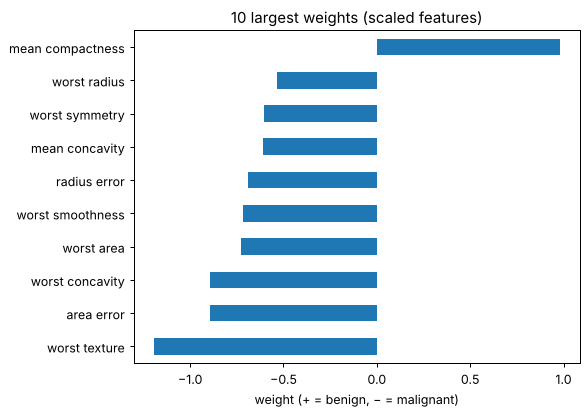

In [4]:
lin = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)).fit(X_train, y_train)
svc = lin[-1]
print("support vectors per class:", svc.n_support_, " total:", len(svc.support_), "of", len(X_train))
print("margin width 2/||w|| =", round(2 / np.linalg.norm(svc.coef_), 3))

names = load_breast_cancer().feature_names
weights = pd.Series(svc.coef_[0], index=names)
top = weights.reindex(weights.abs().sort_values(ascending=False).index)[:10]
top.sort_values().plot(kind="barh", title="10 largest weights (scaled features)")
plt.xlabel("weight (+ = benign, − = malignant)")
plt.show()

## 5. The effect of C
Small C = wide margin, many support vectors. Large C = narrow margin, fewer support vectors.

In [5]:
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C))
    cv = cross_val_score(pipe, X_train, y_train, cv=5).mean()
    n_sv = len(pipe.fit(X_train, y_train)[-1].support_)
    print(f"C = {C:<6} support vectors = {n_sv:3}   mean CV accuracy = {cv:.3f}")

C = 0.001  support vectors = 205   mean CV accuracy = 0.930
C = 0.01   support vectors =  97   mean CV accuracy = 0.977
C = 0.1    support vectors =  47   mean CV accuracy = 0.967
C = 1      support vectors =  34   mean CV accuracy = 0.965
C = 10     support vectors =  26   mean CV accuracy = 0.948
C = 100    support vectors =  26   mean CV accuracy = 0.948


## 6. Kernels and γ
For the RBF kernel, γ controls how far each support vector's influence reaches.

In [6]:
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel=kernel))
    print(f"{kernel:8} mean CV accuracy = {cross_val_score(pipe, X_train, y_train, cv=5).mean():.3f}")

linear   mean CV accuracy = 0.965
poly     mean CV accuracy = 0.894
rbf      mean CV accuracy = 0.965
sigmoid  mean CV accuracy = 0.969


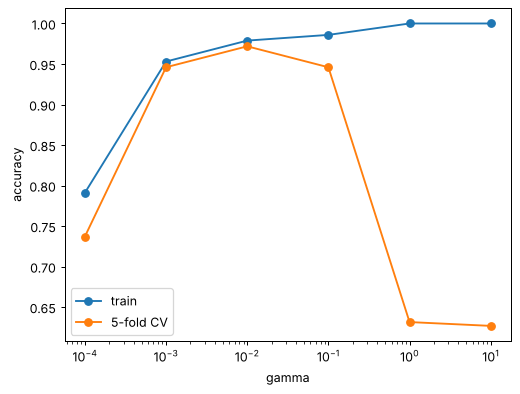

In [7]:
gammas = [0.0001, 0.001, 0.01, 0.1, 1, 10]
train_acc, cv_acc = [], []
for g in gammas:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma=g))
    train_acc.append(pipe.fit(X_train, y_train).score(X_train, y_train))
    cv_acc.append(cross_val_score(pipe, X_train, y_train, cv=5).mean())

plt.semilogx(gammas, train_acc, "o-", label="train")
plt.semilogx(gammas, cv_acc, "o-", label="5-fold CV")
plt.xlabel("gamma")
plt.ylabel("accuracy")
plt.legend()
plt.show()

Large γ: training accuracy reaches 1.0 while CV accuracy collapses: every support vector only covers its own tiny neighborhood (overfitting).

## 7. Tune C and γ together with GridSearchCV

In [8]:
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
params = {"svc__C": [0.1, 1, 10, 100],
          "svc__gamma": [0.0001, 0.001, 0.01, 0.1, 1]}
grid = GridSearchCV(pipe, params, cv=5).fit(X_train, y_train)

print("best parameters:", grid.best_params_)
print("best CV accuracy:", round(grid.best_score_, 3))
print("test accuracy:   ", round(grid.score(X_test, y_test), 3))

scores = pd.DataFrame(grid.cv_results_["mean_test_score"].reshape(4, 5),
                      index=params["svc__C"], columns=params["svc__gamma"])
scores.index.name, scores.columns.name = "C", "gamma"
scores.round(3)

best parameters: {'svc__C': 10, 'svc__gamma': 0.001}
best CV accuracy: 0.977
test accuracy:    0.979


gamma,0.0001,0.0010,0.0100,0.1000,1.0000
C,,,,,
0.1,0.627,0.709,0.944,0.941,0.627
1.0,0.737,0.946,0.972,0.946,0.631
10.0,0.946,0.977,0.962,0.941,0.631
100.0,0.977,0.969,0.962,0.944,0.631


## 8. Evaluate the best model

              precision    recall  f1-score   support

   malignant       0.98      0.96      0.97        53
      benign       0.98      0.99      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143


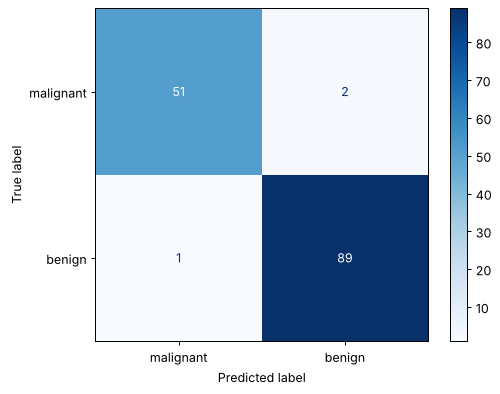

In [9]:
best = grid.best_estimator_
pred = best.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["malignant", "benign"], cmap="Blues")
plt.show()
print(classification_report(y_test, pred, target_names=["malignant", "benign"]))

SVC gives **scores** (`decision_function`), not probabilities. Set `probability=True` if you need `predict_proba` (it trains slower).

In [10]:
print("decision scores:", best.decision_function(X_test[:5]).round(2))
print("predicted class:", best.predict(X_test[:5]))

decision scores: [ 1.04 -2.06  0.19  0.79  0.05]
predicted class: [1 0 1 1 1]


# Part 2: Multiclass — handwritten digits
## 9. Load the Digits dataset
SVC handles many classes automatically (one-vs-one: one SVM per pair of classes, then a vote).

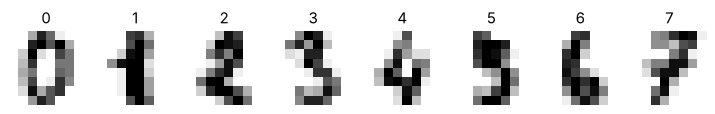

In [11]:
digits = load_digits()
fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for ax, img, label in zip(axes, digits.images, digits.target):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.show()

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.25, stratify=digits.target, random_state=0)

test accuracy: 0.982


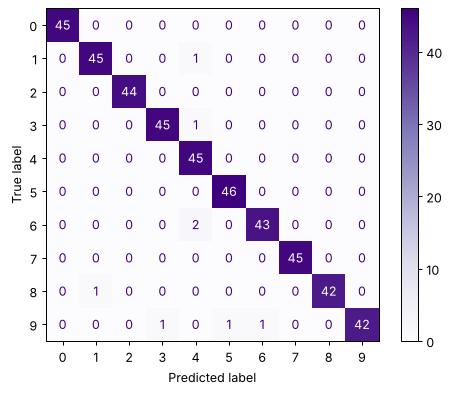

In [12]:
digit_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10)).fit(Xd_train, yd_train)
print("test accuracy:", round(digit_svm.score(Xd_test, yd_test), 3))
ConfusionMatrixDisplay.from_predictions(yd_test, digit_svm.predict(Xd_test), cmap="Purples")
plt.show()

# Part 3: Regression with SVR
## 10. SVR on the Diabetes dataset
SVR fits a tube of width ε around the prediction: errors smaller than ε cost nothing.

In [13]:
Xr, yr = load_diabetes(return_X_y=True)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.25, random_state=42)

for C in [1, 10, 100, 1000]:
    svr = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=C, epsilon=10))
    svr.fit(Xr_train, yr_train)
    print(f"SVR  C = {C:<5} test R² = {svr.score(Xr_test, yr_test):.3f}  "
          f"support vectors = {len(svr[-1].support_)}")

lin_reg = LinearRegression().fit(Xr_train, yr_train)
print(f"linear regression    test R² = {lin_reg.score(Xr_test, yr_test):.3f}")

SVR  C = 1     test R² = 0.195  support vectors = 302
SVR  C = 10    test R² = 0.509  support vectors = 292
SVR  C = 100   test R² = 0.497  support vectors = 277
SVR  C = 1000  test R² = 0.107  support vectors = 293
linear regression    test R² = 0.485


## Summary
| Step | Code |
|---|---|
| Scale + classifier | `make_pipeline(StandardScaler(), SVC(kernel="rbf"))` |
| Linear model internals | `coef_`, `intercept_`, `support_vectors_`, `n_support_` |
| Margin vs. violations | `C` (small = wide margin) |
| Kernel reach | `gamma` (large = wiggly boundary) |
| Tune | `GridSearchCV` over `C` and `gamma` |
| Regression | `SVR(C=..., epsilon=...)` |

**Try it:** in section 9, replace the RBF kernel with `kernel="linear"` and compare the accuracy on the digits.